## Solution for Assignment 02 Question 3

### Setup

In [21]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import copy

SEED = 0

### CONSTANTS ###
BATCH_SIZE = 256
EPOCHS = 10
LR = 0.0001


class ResNet18(nn.Module):
    def __init__(self):
        super(ResNet18, self).__init__()
        self.relu = nn.ReLU()
        self.skip = nn.Identity()

        self.in_block = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False), 
            nn.BatchNorm2d(64), 
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1), 
            nn.ReLU()
        )

        self.block_1a = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
        )

        self.block_1b = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
        )

        self.block_2a = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
        )
        self.conv_skip_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=1, stride=2, bias=False),
            nn.BatchNorm2d(128)
        )

        self.block_2b = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
        )

        self.block_3a = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(256),
        )
        self.conv_skip_3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=1, stride=2, bias=False),
            nn.BatchNorm2d(256),
        )

        self.block_3b = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(256),
        )

        self.block_4a = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
        )
        self.conv_skip_4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=1, stride=2, bias=False),
            nn.BatchNorm2d(512),
        )

        self.block_4b = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
        )
        
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, 10)
    

    def forward(self, x):
        x = self.in_block(x)

        x = self.block_1a(x) + self.skip(x)
        x = self.relu(x)

        x = self.block_1b(x) + self.skip(x)
        x = self.relu(x)

        x = self.block_2a(x) + self.conv_skip_2(x)
        x = self.relu(x)
        x = self.block_2b(x) + self.skip(x)
        x = self.relu(x)

        x = self.block_3a(x) + self.conv_skip_3(x)
        x = self.relu(x)
        x = self.block_3b(x) + self.skip(x)
        x = self.relu(x)

        x = self.block_4a(x) + self.conv_skip_4(x)
        x = self.relu(x)
        x = self.block_4b(x) + self.skip(x)
        x = self.relu(x)
        
        x = self.avgpool(x)
        x = x.flatten(1)
        x = self.fc(x)
        
        return x


### MODEL ###
# Initialize the custom ResNet18 model
resnet18_model = ResNet18()

In [22]:
### DATA ###

# Transform to convert FMNIST data into normalized tensors
fmnist_data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


# Init train and test datasets
train_data = datasets.FashionMNIST(
    root='/datasets/FMNIST/',
    train=True,
    download=True,
    transform=fmnist_data_transform
)

test_data = datasets.FashionMNIST(
    root="/datasets/FMNIST/",
    train=False,
    download=True,
    transform=fmnist_data_transform,
)

# Will need validation for early stopping. To do that, I split the training dataset
# 90% for training, 10% for validation
val_size = int(0.1 * len(train_data))
train_size = len(train_data) - val_size

train_set, val_set = torch.utils.data.random_split(
    train_data, [train_size, val_size], generator=torch.Generator().manual_seed(SEED)
)

# Define dataloaders
FMNIST_train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
FMNIST_val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
FMNIST_test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

### a) Training with L2 Regularization

In [23]:
### L2 Regularization TRAIN and TEST ###
LAMBDA = 0.0001


# Training with l2 regularization
def train_l2_regularize(
    epochs, learning_rate, model, train_loader, test_loader, lambda_val
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use Adam with no weight decay (L2 regularization is added manually)
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=0
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()
            # Add l2 regularization term defined as lambda / 2 * sum of squared parameters
            loss += lambda_val * sum((p**2).sum() for p in model.parameters()) / 2

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


l2_regularization_model = copy.deepcopy(resnet18_model)
train_accs_l2, test_accs_l2 = train_l2_regularize(
    EPOCHS, LR, l2_regularization_model, FMNIST_train_loader, FMNIST_test_loader, LAMBDA
)

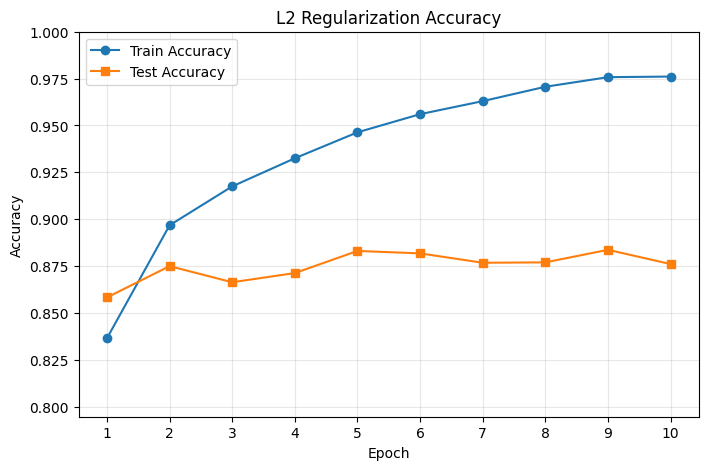

Final train accuracy: 0.9760925925925926, average train accuracy: 0.9371222222222222
Final test accuracy: 0.8761, average test accuracy: 0.8749499999999999


In [24]:
# Plotting script
import matplotlib.pyplot as plt

def plot_accs(title, train_accs, test_accs):
    epochs = range(1, len(train_accs) + 1)
    
    plt.figure(figsize=(8, 5))

    plt.plot(epochs, train_accs, marker="o", label="Train Accuracy")
    plt.plot(epochs, test_accs, marker="s", label="Test Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.xticks(epochs)
    plt.ylim(min(0.8, 0.95 * min(min(train_accs), min(test_accs))), 1)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
def print_stats(train_accs, test_accs):
    print(f'Final train accuracy: {train_accs[-1]}, average train accuracy: {sum(train_accs) / len(train_accs)}')
    print(f'Final test accuracy: {test_accs[-1]}, average test accuracy: {sum(test_accs) / len(test_accs)}')

plot_accs("L2 Regularization Accuracy", train_accs_l2, test_accs_l2)
print_stats(train_accs_l2, test_accs_l2)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0.0001 = 10^{-4}$

Weight Decay of Adam: $0$

### b) Training with Adam with weight decay

In [25]:
### Weight-Decay Adam TRAIN and TEST ###
weight_decay = LAMBDA


# Training with weight-decay Adam
def train_weight_decay(
    epochs, learning_rate, model, train_loader, test_loader, weight_decay_const
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use Adam with weight decay
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


weight_decay_model = copy.deepcopy(resnet18_model)
train_accs_wd, test_accs_wd = train_weight_decay(
    EPOCHS,
    LR,
    weight_decay_model,
    FMNIST_train_loader,
    FMNIST_test_loader,
    weight_decay,
)

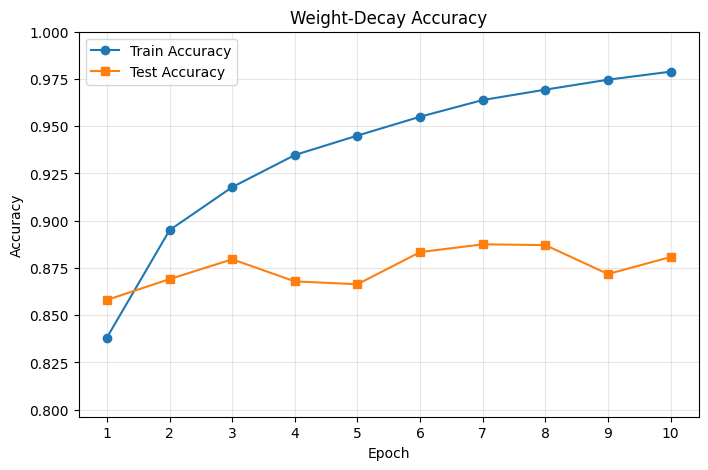

Final train accuracy: 0.9788703703703704, average train accuracy: 0.9372518518518518
Final test accuracy: 0.8808, average test accuracy: 0.87517


In [26]:
plot_accs("Weight-Decay Accuracy", train_accs_wd, test_accs_wd)
print_stats(train_accs_wd, test_accs_wd)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0$

Weight Decay of Adam: $0.0001 = 10^{-4}$

### c) AdamW with weight decay

In [27]:
### Weight-Decay AdamW TRAIN and TEST ###
weight_decay_AdamW = LAMBDA


# Training with weight-decay AdamW
def train_weight_decay_AdamW(
    epochs, learning_rate, model, train_loader, test_loader, weight_decay_const
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use AdamW with weight decay
    optim = torch.optim.AdamW(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


weight_decay_AdamW_model = copy.deepcopy(resnet18_model)
train_accs_wd_AdamW, test_accs_wd_AdamW = train_weight_decay_AdamW(
    EPOCHS,
    LR,
    weight_decay_AdamW_model,
    FMNIST_train_loader,
    FMNIST_test_loader,
    weight_decay_AdamW,
)

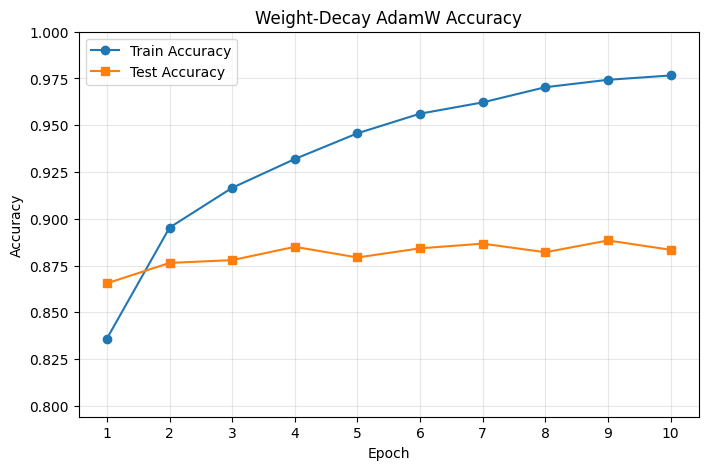

Final train accuracy: 0.9766111111111111, average train accuracy: 0.9365111111111111
Final test accuracy: 0.8834, average test accuracy: 0.88089


In [28]:
plot_accs("Weight-Decay AdamW Accuracy", train_accs_wd_AdamW, test_accs_wd_AdamW)
print_stats(train_accs_wd_AdamW, test_accs_wd_AdamW)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0$

Weight Decay of AdamW: $0.0001 = 10^{-4}$

### d) All methods with early stopping

In [29]:
### L2 Regularization TRAIN and TEST  with early stopping ###
LAMBDA = 0.0001


# Training with l2 regularization with early stopping
def train_l2_regularize_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    lambda_val,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use Adam with no weight decay (L2 regularization is added manually)
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=0
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()
            # Add l2 regularization term defined as lambda / 2 * sum of squared parameters
            loss += lambda_val * sum((p**2).sum() for p in model.parameters()) / 2

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


l2_regularization_model = copy.deepcopy(resnet18_model)
train_accs_l2_early_stop, test_accs_l2_early_stop, valid_loss_l2_early_stop = (
    train_l2_regularize_early_stop(
        EPOCHS,
        LR,
        l2_regularization_model,
        FMNIST_train_loader,
        FMNIST_val_loader,
        FMNIST_test_loader,
        LAMBDA,
    )
)

Early stopping at epoch 5


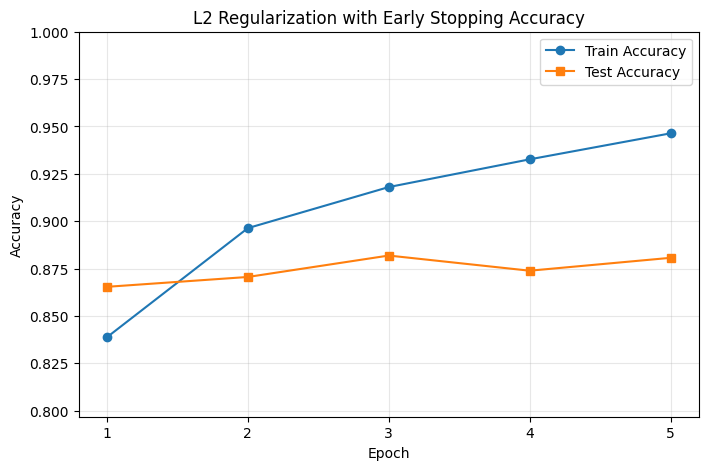

Final train accuracy: 0.9463888888888888, average train accuracy: 0.9064518518518518
Final test accuracy: 0.8807, average test accuracy: 0.8745
Final 2 validation losses: 0.34542136764526365, 0.34091627748807274


In [30]:
plot_accs(
    "L2 Regularization with Early Stopping Accuracy",
    train_accs_l2_early_stop,
    test_accs_l2_early_stop,
)
print_stats(train_accs_l2_early_stop, test_accs_l2_early_stop)
print(
    f"Final 2 validation losses: {valid_loss_l2_early_stop[-2]}, {valid_loss_l2_early_stop[-1]}"
)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0.0001 = 10^{-4}$

Weight Decay of Adam: $0$

Early stop triggered at epoch $5$

In [31]:
### Weight-Decay Adam TRAIN and TEST with early stopping ###
weight_decay = LAMBDA

# Training with Weight-Decay Adam and early stopping
def train_weight_decay_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    weight_decay_const,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use Adam
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


weight_decay_model = copy.deepcopy(resnet18_model)
(
    train_accs_weight_decay_early_stop,
    test_accs_weight_decay_early_stop,
    valid_loss_weight_decay_early_stop,
) = train_weight_decay_early_stop(
    EPOCHS,
    LR,
    weight_decay_model,
    FMNIST_train_loader,
    FMNIST_val_loader,
    FMNIST_test_loader,
    weight_decay,
)

Early stopping at epoch 6


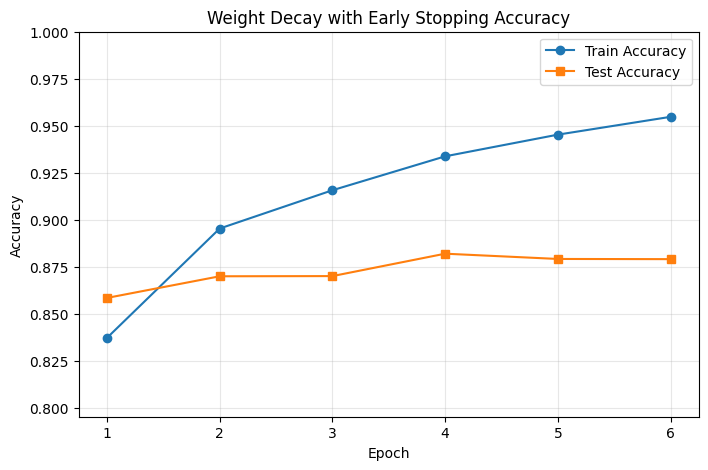

Final train accuracy: 0.9547962962962963, average train accuracy: 0.9137623456790124
Final test accuracy: 0.8792, average test accuracy: 0.87325
Final 2 validation losses: 0.3498074787457784, 0.3766766368548075


In [32]:
plot_accs(
    "Weight Decay with Early Stopping Accuracy",
    train_accs_weight_decay_early_stop,
    test_accs_weight_decay_early_stop,
)
print_stats(train_accs_weight_decay_early_stop, test_accs_weight_decay_early_stop)
print(
    f"Final 2 validation losses: {valid_loss_weight_decay_early_stop[-2]}, {valid_loss_weight_decay_early_stop[-1]}"
)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0$

Weight Decay of Adam: $0.0001 = 10^{-4}$

Early stop triggered at epoch $6$

In [33]:
### Weight-Decay Adam TRAIN and TEST with early stopping ###
weight_decay = LAMBDA

# Training with Weight-Decay AdamW and early stopping
def train_weight_decay_AdamW_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    weight_decay_const,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use AdamW
    optim = torch.optim.AdamW(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


weight_decay_AdamW_model = copy.deepcopy(resnet18_model)
(
    train_accs_weight_decay_AdamW_early_stop,
    test_accs_weight_decay_AdamW_early_stop,
    valid_loss_weight_decay_AdamW_early_stop,
) = train_weight_decay_AdamW_early_stop(
    EPOCHS,
    LR,
    weight_decay_AdamW_model,
    FMNIST_train_loader,
    FMNIST_val_loader,
    FMNIST_test_loader,
    weight_decay,
)

Early stopping at epoch 6


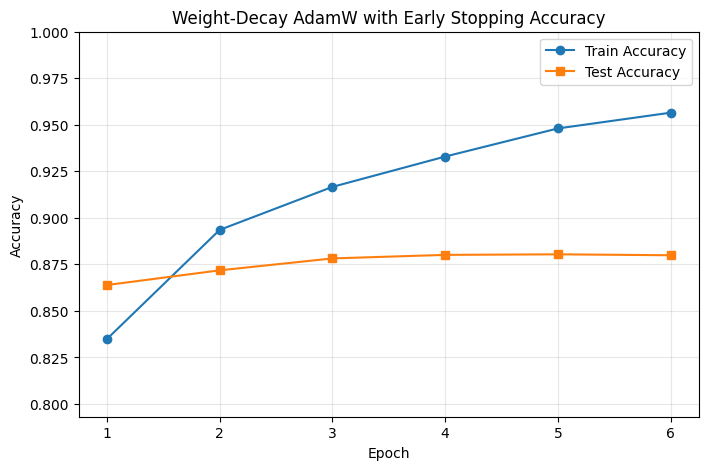

Final train accuracy: 0.9565, average train accuracy: 0.9137530864197531
Final test accuracy: 0.8799, average test accuracy: 0.8757166666666666
Final 2 validation losses: 0.3366601941585541, 0.37001046641667684


In [34]:
plot_accs(
    "Weight-Decay AdamW with Early Stopping Accuracy",
    train_accs_weight_decay_AdamW_early_stop,
    test_accs_weight_decay_AdamW_early_stop,
)
print_stats(train_accs_weight_decay_AdamW_early_stop, test_accs_weight_decay_AdamW_early_stop)
print(
    f"Final 2 validation losses: {valid_loss_weight_decay_AdamW_early_stop[-2]}, {valid_loss_weight_decay_AdamW_early_stop[-1]}"
)

Learning Rate $\eta = 0.0001 = 10^{-4}$

Regularization Hyperparameter $\lambda = 0$

Weight Decay of AdamW: $0.0001 = 10^{-4}$

Early stop triggered at epoch $6$

**Change in training and testing performance.** I used early stopping with a patience of 2 (i.e. the training stops if the validation loss does not improve for 2 consecutive epochs), with 10% of the training data used for validation. L2 regularization stopped after 5 epochs, Adam with weight decay stopped after 6 epochs, and AdamW with weight decay also stopped after 6 epochs. The training and testing accuracies showed different behaviors for each method. 

- L2 regularization: Training accuracy decreased from 97.61% to 94.64%, while test accuracy increased from 87.61% to 88.07%.

- Adam with weight decay: Training accuracy decreased from 97.89% to 95.48%, while test accuracy slightly decreased from 88.08% to 87.92%.

- AdamW with weight decay: Training accuracy decreased from 97.66% to 95.65%, while test accuracy slightly decreased from 88.34% to 87.99%.

In all cases, a notable decrease in computational cost (40%-50%) resulted in lower training accuracy while maintaining comparable testing performance. 